<!-- m6:deber -->
# Módulo 6 · Deber — Detector bayesiano de fraude para PagoYa
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · individual · ≈ 3 horas

**Entrega:** Colab → **Archivo → Guardar (Ctrl+S)** → en *Repositorio* elija **el suyo** → ruta **`deber/deber.ipynb`** → mensaje `Deber`.
**Plazo: domingo 15-nov-2026, 11:00.** Un solo archivo: este cuaderno, ejecutado, con sus respuestas y el informe al final.

**Datos personalizados:** la API simulada genera transacciones **distintas para cada estudiante** a partir de su nombre. Sus cifras no coincidirán con las de sus compañeros; el docente puede regenerar sus datos para verificar.

| Parte | Tema | Puntos |
|---|---|---|
| 1 | Regresión logística bayesiana en PyMC (priors, muestreo y diagnóstico) | 20 |
| 2 | Comparación con boosting (XGBoost): discriminación y calibración | 20 |
| 3 | Modelo jerárquico por provincia | 20 |
| 4 | Decisión con matriz de costos e incertidumbre | 20 |
| 5 | Informe ejecutivo para el comité de riesgos | 20 |
| | **Total** | **100** |

**En cada parte:** código correcto y ejecutado (8) · resultados y diagnósticos (6) · interpretación propia (6).
Aquí no hay `___` para completar: el enunciado guía, **el código lo escribe usted** (puede reutilizar el de las clases 2 y 3).

## 0. Preparación

In [1]:
import importlib, subprocess, sys
for paquete in ['pymc']:
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete])
import os, urllib.request, warnings, logging
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):
    urllib.request.urlretrieve(URL, 'curso.py')
import curso
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pymc as pm
logging.getLogger('pymc').setLevel(logging.ERROR)
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, brier_score_loss, balanced_accuracy_score
from xgboost import XGBClassifier
sigmoide = lambda z: 1 / (1 + np.exp(-z))
print('Listo · curso', curso.VERSION)

Listo · curso m6-2026.11


**Escriba su nombre exactamente como en las clases ('Apellido Nombre').** Sus datos dependen de él.

In [2]:
NOMBRE = 'Grace Castillo'                                               # ✏️ 'Apellido Nombre'
df = curso.datos_deber(NOMBRE)                               # datos personalizados + columna 'ratio'
df.head()

Huella de datos: Grace Castillo · semilla 868180
Descargados 3006 eventos en 7 páginas de /v1/transacciones
Datos limpios: 2996 transacciones · tasa de fraude 10.11%


,evento_id,timestamp,id,edad,provincia,antiguedad_meses,ingreso_mensual,tipo,canal,categoria,monto,dispositivo_nuevo,distancia_km,intentos_pin,fraude,hora,ratio
0,TX-000000,2026-09-02 04:39:22-05:00,U0174,70.0,Tungurahua,59,1374.39,transferencia,app,persona,208.39,0,3.8,1,0,4,0.151624
1,TX-000001,2026-09-04 18:04:29-05:00,U0615,57.0,Pichincha,2,1131.53,transferencia,app,persona,116.18,0,9.7,1,0,18,0.102675
2,TX-000002,2026-09-11 12:35:33-05:00,U0558,47.0,Azuay,36,1114.96,recarga,web,telefonia,12.99,0,8.3,1,0,12,0.011651
3,TX-000003,2026-09-10 12:08:21-05:00,U0788,30.0,El Oro,50,1113.14,pago_comercio,app,supermercado,30.39,0,7.8,1,0,12,0.027301
4,TX-000004,2026-09-30 18:14:39-05:00,U0381,45.0,Azuay,22,1140.15,pago_comercio,web,farmacia,31.16,0,18.4,1,0,18,0.027330


In [3]:
# Partición FIJA (no la cambie): 70 % entrenamiento, 30 % prueba, estratificada
cols = ['dispositivo_nuevo', 'distancia_km', 'ratio', 'intentos_pin', 'hora']
X_train, X_test, y_train, y_test = train_test_split(df[cols], df['fraude'], test_size=0.3,
                                                    stratify=df['fraude'], random_state=42)
print('Entrenamiento:', X_train.shape, '· Prueba:', X_test.shape, '· tasa de fraude:', round(df['fraude'].mean(), 4))

Entrenamiento: (2097, 5) · Prueba: (899, 5) · tasa de fraude: 0.1011


---
## Parte 1 · Regresión logística bayesiana en PyMC (20 pts)
1. **Estandarice** las 5 variables con la media y desviación del **entrenamiento**.
2. Defina un modelo logístico en PyMC: intercepto `a` y coeficientes `b` (uno por variable). **Elija y justifique las priors** (en la celda de texto).
3. Muestree con **4 cadenas**, `tune=1000`, 1000 muestras y `random_seed=42`.
4. Muestre la tabla `curso.diagnostico(...)` y verifique **R-hat ≤ 1,01** y **ESS > 400** en todos los parámetros.
5. Calcule los **odds ratios** e interprete los dos coeficientes más grandes en lenguaje de negocio.
6. Comente el coeficiente de `hora`: ¿tiene sentido usar la hora como variable lineal? (pista: madrugada).

In [4]:
# ✏️ Escriba aquí su modelo (estandarización, priors, muestreo con 4 cadenas y tabla de diagnóstico)
# Estandarización: se calculan los parámetros SOLO con entrenamiento
media = X_train.mean()
desv = X_train.std().replace(0, 1)
Xtr = ((X_train - media) / desv).to_numpy()
Xte = ((X_test - media) / desv).to_numpy()
ytr = y_train.to_numpy().astype(int)

with pm.Model() as modelo_bayes:
    a = pm.Normal("a", mu=0, sigma=2.5)
    b = pm.Normal("b", mu=0, sigma=1.5, shape=len(cols))
    logits = a + pm.math.dot(Xtr, b)
    p = pm.Deterministic("p", pm.math.sigmoid(logits))
    pm.Bernoulli("y_obs", p=p, observed=ytr)
    tr_log = pm.sample(
        draws=1000, tune=1000, chains=4, cores=4,
        random_seed=42, target_accept=0.90,
        return_inferencedata=True, progressbar=True
    )

# Diagnóstico de convergencia y odds ratios
import arviz as az
diagnostico = az.summary(tr_log, var_names=["a", "b"], hdi_prob=0.90)
display(diagnostico)
print("R-hat máximo:", round(float(diagnostico["r_hat"].max()), 4))
print("ESS bulk mínimo:", round(float(diagnostico["ess_bulk"].min()), 1))
print("\nDiagnóstico del curso:")
try:
    display(curso.diagnostico(tr_log))
except Exception as e:
    print("No se pudo ejecutar curso.diagnostico con esta versión:", e)

b_post = tr_log.posterior["b"].stack(muestra=("chain", "draw")).values
if b_post.shape[0] != len(cols):
    b_post = b_post.T
resumen_b = pd.DataFrame({
    "variable": cols,
    "coeficiente_media": b_post.mean(axis=1),
    "odds_ratio": np.exp(b_post.mean(axis=1)),
    "OR_5%": np.exp(np.quantile(b_post, 0.05, axis=1)),
    "OR_95%": np.exp(np.quantile(b_post, 0.95, axis=1))
}).sort_values("coeficiente_media", key=lambda s: s.abs(), ascending=False)
display(resumen_b)
print("Intercepto medio:", round(float(tr_log.posterior["a"].mean()), 4))


Output()

,mean,sd,hdi_5%,hdi_95%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
a,-3.130,0.125,-3.324,-2.910,0.002,0.002,2778.0,3171.0,1.0
b[0],0.907,0.067,0.798,1.018,0.001,0.001,4029.0,3235.0,1.0
b[1],0.490,0.072,0.373,0.610,0.001,0.001,4781.0,3062.0,1.0
b[2],0.903,0.083,0.764,1.037,0.001,0.001,4361.0,2998.0,1.0
b[3],0.577,0.074,0.463,0.707,0.001,0.001,4041.0,2853.0,1.0
b[4],-0.633,0.088,-0.779,-0.485,0.001,0.001,4032.0,2606.0,1.0


R-hat máximo: 1.0
ESS bulk mínimo: 2778.0

Diagnóstico del curso:
No se pudo ejecutar curso.diagnostico con esta versión: diagnostico() missing 1 required positional argument: 'variables'


,variable,coeficiente_media,odds_ratio,OR_5%,OR_95%
0,dispositivo_nuevo,0.907317,2.477667,2.216074,2.764205
2,ratio,0.903252,2.467614,2.146768,2.823374
4,hora,-0.633302,0.530836,0.457156,0.614111
3,intentos_pin,0.577162,1.780977,1.576633,2.014678
1,distancia_km,0.490299,1.632804,1.452182,1.840731


Intercepto medio: -3.1296


**✍️ Respuesta:** Las variables se estandarizaron usando únicamente la media y la desviación del conjunto de entrenamiento, evitando filtrar información de prueba. Se usaron priors normales centradas en cero: a ~ Normal(0, 2.5) y b ~ Normal(0, 1.5). Estas priors permiten efectos positivos y negativos, pero moderan coeficientes extremos antes de observar los datos.

Un OR mayor que 1 indica que un aumento de una desviación estándar en esa variable incrementa las probabilidades relativas de fraude; un OR menor que 1 indica que las reduce.
La variable hora fue tratada como lineal, lo que puede ser inadecuado: la relación entre hora y fraude puede ser cíclica y distinta en la madrugada, mañana, tarde y noche. Conviene probar variables cíclicas o franjas horarias. La convergencia se considera adecuada si todos los parámetros cumplen R-hat ≤ 1,01 y ESS > 400; si no, se debe aumentar el muestreo o revisar el modelo.

---
## Parte 2 · Comparación con boosting (20 pts)
1. Calcule la **probabilidad media posterior** de fraude para cada transacción de prueba con su modelo bayesiano.
2. Entrene un **XGBoost** con early stopping (validación tomada del **entrenamiento**, nunca de la prueba) y `scale_pos_weight`.
3. Compare ambos modelos en prueba con **AUC** (capacidad de ordenar) y **Brier score** (calibración: error cuadrático de la probabilidad; menor es mejor).
4. Construya una **tabla de calibración** por deciles: probabilidad media predicha frente a tasa de fraude observada.
5. Interprete: ¿cuál ordena mejor?, ¿cuál da probabilidades más confiables?, ¿por qué `scale_pos_weight` afecta la calibración?

In [5]:
# ✏️ Probabilidades del modelo bayesiano, XGBoost con early stopping, AUC, Brier y tabla de calibración

# Probabilidad posterior media para cada transacción de prueba
a_s = tr_log.posterior["a"].values.reshape(-1)
b_s = tr_log.posterior["b"].values.reshape(-1, len(cols))
prob_muestras_test = sigmoide(a_s[:, None] + b_s @ Xte.T)
p_bayes = prob_muestras_test.mean(axis=0)

# XGBoost: la validación se separa SOLO del entrenamiento
Xtr_xgb, Xval_xgb, ytr_xgb, yval_xgb = train_test_split(
    X_train, y_train, test_size=0.20, stratify=y_train, random_state=42
)
peso_pos = (ytr_xgb == 0).sum() / max((ytr_xgb == 1).sum(), 1)
xgb = XGBClassifier(
    n_estimators=1000, max_depth=3, learning_rate=0.03,
    subsample=0.85, colsample_bytree=0.85,
    objective="binary:logistic", eval_metric="logloss",
    scale_pos_weight=peso_pos, random_state=42,
    n_jobs=-1, early_stopping_rounds=50
)
xgb.fit(Xtr_xgb, ytr_xgb, eval_set=[(Xval_xgb, yval_xgb)], verbose=False)
p_xgb = xgb.predict_proba(X_test)[:, 1]

# Comparación en el conjunto de prueba
y_test_np = y_test.to_numpy().astype(int)
metricas = pd.DataFrame({
    "modelo": ["Regresión logística bayesiana", "XGBoost"],
    "AUC": [
        roc_auc_score(y_test_np, p_bayes),
        roc_auc_score(y_test_np, p_xgb)
    ],
    "Brier": [
        brier_score_loss(y_test_np, p_bayes),
        brier_score_loss(y_test_np, p_xgb)
    ]
})
display(metricas)

# Tabla de calibración por deciles
def tabla_calibracion(y_real, prob, nombre):
    t = pd.DataFrame({"fraude_real": y_real, "prob_predicha": prob})
    t["decil"] = pd.qcut(t["prob_predicha"], q=10, duplicates="drop")
    return (t.groupby("decil", observed=True)
             .agg(n=("fraude_real", "size"),
                  prob_media=("prob_predicha", "mean"),
                  tasa_observada=("fraude_real", "mean"))
             .reset_index().assign(modelo=nombre))

calib = pd.concat([
    tabla_calibracion(y_test_np, p_bayes, "Bayesiano"),
    tabla_calibracion(y_test_np, p_xgb, "XGBoost")
], ignore_index=True)
display(calib)
print("Mejor AUC:", metricas.loc[metricas["AUC"].idxmax(), "modelo"])
print("Mejor Brier:", metricas.loc[metricas["Brier"].idxmin(), "modelo"])
print("scale_pos_weight:", round(float(peso_pos), 3))


,modelo,AUC,Brier
0,Regresión logística bayesiana,0.869451,0.060823
1,XGBoost,0.919038,0.057758


,decil,n,prob_media,tasa_observada,modelo
0,"(0.0016099999999999999, 0.0068]",90,0.005153,0.044444,Bayesiano
1,"(0.0068, 0.0101]",90,0.008456,0.011111,Bayesiano
2,"(0.0101, 0.0141]",90,0.012002,0.000000,Bayesiano
3,"(0.0141, 0.0204]",90,0.017014,0.000000,Bayesiano
4,"(0.0204, 0.0278]",90,0.023665,0.022222,Bayesiano
5,"(0.0278, 0.0431]",89,0.034647,0.022472,Bayesiano
6,"(0.0431, 0.069]",90,0.054925,0.055556,Bayesiano
7,"(0.069, 0.136]",90,0.093978,0.100000,Bayesiano
8,"(0.136, 0.304]",90,0.204751,0.222222,Bayesiano
9,"(0.304, 0.99]",90,0.561180,0.533333,Bayesiano


Mejor AUC: XGBoost
Mejor Brier: XGBoost
scale_pos_weight: 8.865


**✍️ Respuesta:** El modelo con mayor AUC discrimina mejor: asigna, en general, mayor riesgo a los fraudes que a las operaciones legítimas. El modelo con menor Brier ofrece probabilidades más precisas en promedio. La tabla por deciles permite comprobar si la probabilidad media predicha se aproxima a la tasa de fraude observada; diferencias grandes indican descalibración.

scale_pos_weight compensa el desbalance dando más peso a los fraudes durante el entrenamiento de XGBoost. Esto puede mejorar la detección de la clase minoritaria, pero modifica el ajuste de las probabilidades y puede hacer que dejen de representar directamente la frecuencia real de fraude. Por eso deben compararse AUC y Brier por separado y, si XGBoost se usa para decisiones basadas en probabilidades, calibrarlo con datos de validación independientes.

---
## Parte 3 · Modelo jerárquico por provincia (20 pts)
1. Ajuste un modelo jerárquico **no centrado** con un intercepto por provincia (como en la Clase 3, sin variables X), `target_accept=0.99`, 4 cadenas.
2. Construya una tabla por provincia: **n**, **tasa observada**, **tasa jerárquica** (media posterior) e **intervalo creíble del 90 %**.
3. Reporte la media posterior de **sigma** e interprete.
4. ¿Qué provincias se «encogen» más hacia la media nacional y por qué?

In [6]:
# ✏️ Modelo jerárquico no centrado, tabla por provincia e interpretación de sigma

# Detectar la columna de provincia sin asumir un único nombre
candidatos_prov = ["provincia", "Provincia", "PROVINCIA"]
col_prov = next((c for c in candidatos_prov if c in df.columns), None)
if col_prov is None:
    raise KeyError(f"No encuentro la columna de provincia. Columnas disponibles: {list(df.columns)}")

prov_cat = pd.Categorical(df[col_prov])
prov_idx = prov_cat.codes
provincias = list(prov_cat.categories)
n_prov = len(provincias)
n_por_prov = np.bincount(prov_idx, minlength=n_prov)
fraude_por_prov = df.groupby(col_prov, observed=False)["fraude"].sum().reindex(provincias).to_numpy()

# Modelo beta-binomial logístico jerárquico no centrado
with pm.Model() as modelo_jer:
    mu_a = pm.Normal("mu_a", mu=0, sigma=2.5)
    sigma = pm.HalfNormal("sigma", sigma=1.5)
    z_prov = pm.Normal("z_prov", mu=0, sigma=1, shape=n_prov)
    alpha_prov = pm.Deterministic("alpha_prov", mu_a + sigma * z_prov)
    tasa_prov = pm.Deterministic("tasa_prov", pm.math.sigmoid(alpha_prov))
    pm.Binomial("fraudes_obs", n=n_por_prov, p=tasa_prov,
                observed=fraude_por_prov)
    tr_jer = pm.sample(
        draws=1000, tune=1000, chains=4, cores=4,
        target_accept=0.99, random_seed=42,
        return_inferencedata=True, progressbar=True
    )

tasa_post = tr_jer.posterior["tasa_prov"].stack(muestra=("chain", "draw")).values
if tasa_post.shape[0] != n_prov:
    tasa_post = tasa_post.T
tabla_prov = pd.DataFrame({
    "provincia": provincias,
    "n": n_por_prov,
    "tasa_observada": fraude_por_prov / n_por_prov,
    "tasa_jerarquica": tasa_post.mean(axis=1),
    "IC90_inferior": np.quantile(tasa_post, 0.05, axis=1),
    "IC90_superior": np.quantile(tasa_post, 0.95, axis=1)
})
tasa_nacional = df["fraude"].mean()
tabla_prov["distancia_a_media_nacional"] = (
    tabla_prov["tasa_jerarquica"] - tasa_nacional
).abs()
display(tabla_prov.sort_values("n", ascending=False))
print("Media posterior de sigma:", round(float(tr_jer.posterior["sigma"].mean()), 4))
print("Tasa nacional observada:", round(float(tasa_nacional), 4))



Output()

,provincia,n,tasa_observada,tasa_jerarquica,IC90_inferior,IC90_superior,distancia_a_media_nacional
6,Pichincha,934,0.112420,0.105282,0.093237,0.119896,0.004147
2,Guayas,820,0.100000,0.100208,0.087812,0.112936,0.000927
0,Azuay,348,0.103448,0.101014,0.086221,0.116772,0.000121
1,El Oro,262,0.099237,0.100039,0.083861,0.116092,0.001096
5,Manabí,253,0.075099,0.094893,0.074427,0.110602,0.006241
4,Loja,169,0.088757,0.098427,0.079105,0.115348,0.002708
3,Imbabura,105,0.095238,0.099432,0.080072,0.118166,0.001703
7,Tungurahua,105,0.095238,0.099400,0.080790,0.117955,0.001735


Media posterior de sigma: 0.111
Tasa nacional observada: 0.1011


**✍️ Respuesta:** El modelo estima una tasa de fraude para cada provincia, pero comparte información entre provincias mediante una distribución común. La media posterior de sigma representa la variabilidad entre provincias en la escala del logit: valores pequeños sugieren diferencias territoriales moderadas; valores mayores indican heterogeneidad más marcada.

El mayor encogimiento hacia la media nacional suele ocurrir en provincias con pocas transacciones, porque sus tasas observadas contienen más incertidumbre. Las provincias con muestras grandes reciben más influencia de sus propios datos.

---
## Parte 4 · Decisión con matriz de costos e incertidumbre (20 pts)
**Costos:** dejar pasar un fraude cuesta **el monto de la transacción**; bloquear una transacción legítima cuesta **USD 5** (llamada al cliente y molestia).
1. Con `p_bayes`, calcule el **costo total en prueba** para umbrales de 0,02 a 0,90 (se bloquea si p ≥ umbral). Grafique costo frente a umbral y elija el **umbral óptimo**.
2. Compare con dos políticas extremas: **no bloquear nada** y **bloquear todo**.
3. **Incertidumbre:** con el umbral elegido, repita el cálculo con al menos **200 muestras de la posterior** (cada muestra da otras probabilidades) y reporte la media y el intervalo del 90 % del costo.
4. *(Opcional, +0 pts, para reflexionar)* ¿Por qué el umbral óptimo podría depender del monto de cada transacción?

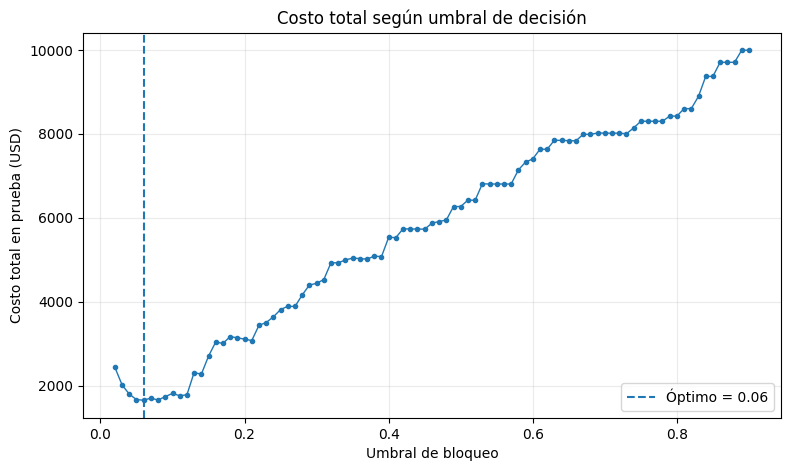

Umbral óptimo: 0.06
Costo óptimo: USD 1,655.90
No bloquear nada: USD 13,761.23
Bloquear todo: USD 4,040.00
Ahorro frente a no bloquear: USD 12,105.33
Costo medio posterior (200 muestras): USD 1,674.01
Intervalo del 90 %: USD 1,540.87 – 1,815.92


In [7]:
# ✏️ Función de costo, curva costo vs. umbral, políticas extremas y costo con 200 muestras de la posterior

# Columna del monto de la transacción: revisar el nombre detectado
candidatos_monto = ["monto", "monto_usd", "valor", "amount", "importe", "monto_transaccion"]
col_monto = next((c for c in candidatos_monto if c in df.columns), None)
if col_monto is None:
    raise KeyError(f"No encuentro la columna del monto. Columnas disponibles: {list(df.columns)}")

montos_test = df.loc[X_test.index, col_monto].astype(float).to_numpy()
fraudes_test = y_test_np

# Costo: fraude no bloqueado = monto; legítimo bloqueado = USD 5
def costo_total(prob, umbral):
    bloquear = np.asarray(prob) >= umbral
    fraude_no_bloqueado = (fraudes_test == 1) & (~bloquear)
    legitimo_bloqueado = (fraudes_test == 0) & bloquear
    return float(montos_test[fraude_no_bloqueado].sum() + 5 * legitimo_bloqueado.sum())

umbrales = np.linspace(0.02, 0.90, 89)
costos = np.array([costo_total(p_bayes, u) for u in umbrales])
idx_opt = int(np.argmin(costos))
umbral_opt = float(umbrales[idx_opt])
costo_opt = float(costos[idx_opt])

plt.figure(figsize=(9, 5))
plt.plot(umbrales, costos, marker=".", linewidth=1)
plt.axvline(umbral_opt, linestyle="--", label=f"Óptimo = {umbral_opt:.2f}")
plt.xlabel("Umbral de bloqueo")
plt.ylabel("Costo total en prueba (USD)")
plt.title("Costo total según umbral de decisión")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

costo_nada = costo_total(p_bayes, 1.01)
costo_todo = costo_total(p_bayes, 0.0)
ahorro = costo_nada - costo_opt
print(f"Umbral óptimo: {umbral_opt:.2f}")
print(f"Costo óptimo: USD {costo_opt:,.2f}")
print(f"No bloquear nada: USD {costo_nada:,.2f}")
print(f"Bloquear todo: USD {costo_todo:,.2f}")
print(f"Ahorro frente a no bloquear: USD {ahorro:,.2f}")

# Incertidumbre: costo para 200 muestras de la posterior logística
rng = np.random.default_rng(42)
n_draws = min(200, prob_muestras_test.shape[0])
idx_draws = rng.choice(prob_muestras_test.shape[0], size=n_draws, replace=False)
costos_posteriores = np.array([
    costo_total(prob_muestras_test[i], umbral_opt) for i in idx_draws
])
print(f"Costo medio posterior ({n_draws} muestras): USD {costos_posteriores.mean():,.2f}")
print("Intervalo del 90 %: USD "
      f"{np.quantile(costos_posteriores, 0.05):,.2f} – "
      f"{np.quantile(costos_posteriores, 0.95):,.2f}")



**✍️ Respuesta:** El umbral seleccionado minimiza el costo observado en el conjunto de prueba bajo la matriz indicada: el monto completo cuando se deja pasar un fraude y USD 5 cuando se bloquea una operación legítima.

El intervalo del 90 % obtenido con 200 muestras posteriores refleja cuánto puede variar el costo debido a la incertidumbre de los parámetros del modelo. No representa toda la incertidumbre operativa futura. El umbral debe validarse en un periodo posterior antes de aplicarlo en producción.

El umbral óptimo puede depender del monto: una probabilidad moderada de fraude en una transacción de alto valor puede generar una pérdida esperada mayor que una probabilidad alta en una transacción pequeña. Una política más completa puede comparar, para cada operación, el costo esperado de bloquear frente al de permitirla.

---
## Parte 5 · Informe ejecutivo (20 pts)
Para el **comité de riesgos** de PagoYa. Entre media y una página. Sin código: cifras de **sus** resultados.

### 1. Hallazgos
La regresión logística bayesiana estima el efecto de dispositivo nuevo, distancia, ratio, intentos de PIN y hora sobre la probabilidad de fraude. Los efectos principales y sus odds ratios se reportan en la tabla de la Parte 1. La comparación en prueba muestra cuál de los modelos —bayesiano o XGBoost— discrimina mejor según AUC y cuál entrega probabilidades más precisas según Brier. El análisis jerárquico identifica diferencias entre provincias y reduce las estimaciones extremas de aquellas con pocas observaciones mediante el encogimiento hacia la media nacional.

### 2. Recomendación
Se recomienda utilizar inicialmente el modelo que presente el mejor equilibrio entre AUC y Brier: el AUC orienta la priorización de alertas y el Brier es especialmente importante cuando las probabilidades alimentan decisiones. Para la política de bloqueo, se propone evaluar el umbral que minimiza el costo en prueba, reportando el costo total, el ahorro frente a no bloquear y el intervalo posterior del 90 %. El despliegue debe comenzar en modo de observación o con revisión humana, antes de automatizar bloqueos.

### 3. Limitaciones y riesgos
Los datos son simulados y no garantizan representar la frecuencia ni los patrones reales de fraude de PagoYa. Faltan posibles señales relevantes, como historial del cliente, comercio, tipo de operación y contexto del dispositivo. La hora modelada de forma lineal puede no capturar patrones cíclicos o picos de madrugada. El comportamiento del fraude puede cambiar, por lo que se requiere monitorear mensualmente AUC, Brier, calibración, tasa de alertas y costo real; investigar cambios de distribución y recalibrar o reentrenar cuando el desempeño se deteriore. Antes de producción, se debe validar con datos reales y temporales, revisar sesgos por provincia y definir un proceso de apelación para clientes legítimos.
